# ChurnGuard AI · 02 — Modelagem, avaliação e explicabilidade

Este notebook apresenta os resultados do pipeline de treino (`ml/src/training/train.py`) e demonstra o uso do
modelo. Relatório completo: `docs/model.md`.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

from ml.src import config
from ml.src.features.build_features import add_features
from ml.src.scoring import ChurnScorer, simulate
from ml.src.viz import style as S

S.apply()
pd.set_option("display.max_columns", 50)
results = json.loads((config.REPORTS_DIR / "training_results.json").read_text(encoding="utf-8"))
meta = json.loads(config.MODEL_METADATA_FILE.read_text(encoding="utf-8"))
FIG = config.MODEL_FIG_DIR

## 1. Engenharia de atributos
Exemplo dos atributos derivados para alguns clientes (todos calculados por linha, sem estado):

In [2]:
base = pd.read_parquet(config.ANALYTICAL_BASE_FILE)
cols = ["media_acessos_semana", "variacao_uso", "tendencia_uso", "meses_consecutivos_queda",
        "taxa_utilizacao_funcionalidades", "percentual_pagamentos_atrasados", "aceleracao_tickets",
        "meses_ate_renovacao", "churn"]
add_features(base.sample(6, random_state=3))[cols].round(3)

,media_acessos_semana,variacao_uso,tendencia_uso,meses_consecutivos_queda,taxa_utilizacao_funcionalidades,percentual_pagamentos_atrasados,aceleracao_tickets,meses_ate_renovacao,churn
47969,26.790,0.000,1.000,0,0.929,0.000,0,11,0
16587,9.931,-0.156,-0.031,0,0.778,0.000,-1,1,0
13439,11.547,0.094,0.040,2,0.500,0.400,0,7,0
26759,27.021,0.445,0.101,1,0.778,0.167,-1,1,0
24066,9.007,0.000,0.167,0,0.071,0.500,3,11,0
17830,6.236,-0.123,-0.008,0,0.556,0.000,1,1,0


## 2. Divisão temporal e validação cruzada

In [3]:
print(json.dumps(results["split"], indent=2, ensure_ascii=False))

{
  "train_start": "2024-06-30",
  "train_end": "2025-09-30",
  "test_start": "2025-12-31",
  "test_end": "2026-07-31",
  "train_rows": 37077,
  "test_rows": 27792,
  "train_churn_rate": 0.07913261590743588,
  "test_churn_rate": 0.08757915947035118,
  "cv_folds": [
    {
      "treino_ate": "2024-10-31",
      "validacao": "2025-01-31 → 2025-03-31"
    },
    {
      "treino_ate": "2025-01-31",
      "validacao": "2025-04-30 → 2025-06-30"
    },
    {
      "treino_ate": "2025-04-30",
      "validacao": "2025-07-31 → 2025-09-30"
    }
  ]
}


## 3. Modelos: inicial × ajustado

,modelo,CV PR-AUC inicial,CV PR-AUC ajustado,teste ROC-AUC,teste PR-AUC,teste Brier
0,Regressão Logística,0.2195,0.2201,0.7695,0.2488,0.0730
1,Random Forest,0.2338,0.2494,0.7833,0.2730,0.0717
2,Gradient Boosting (HistGradientBoosting),0.2268,0.2600,0.7940,0.2984,0.0705


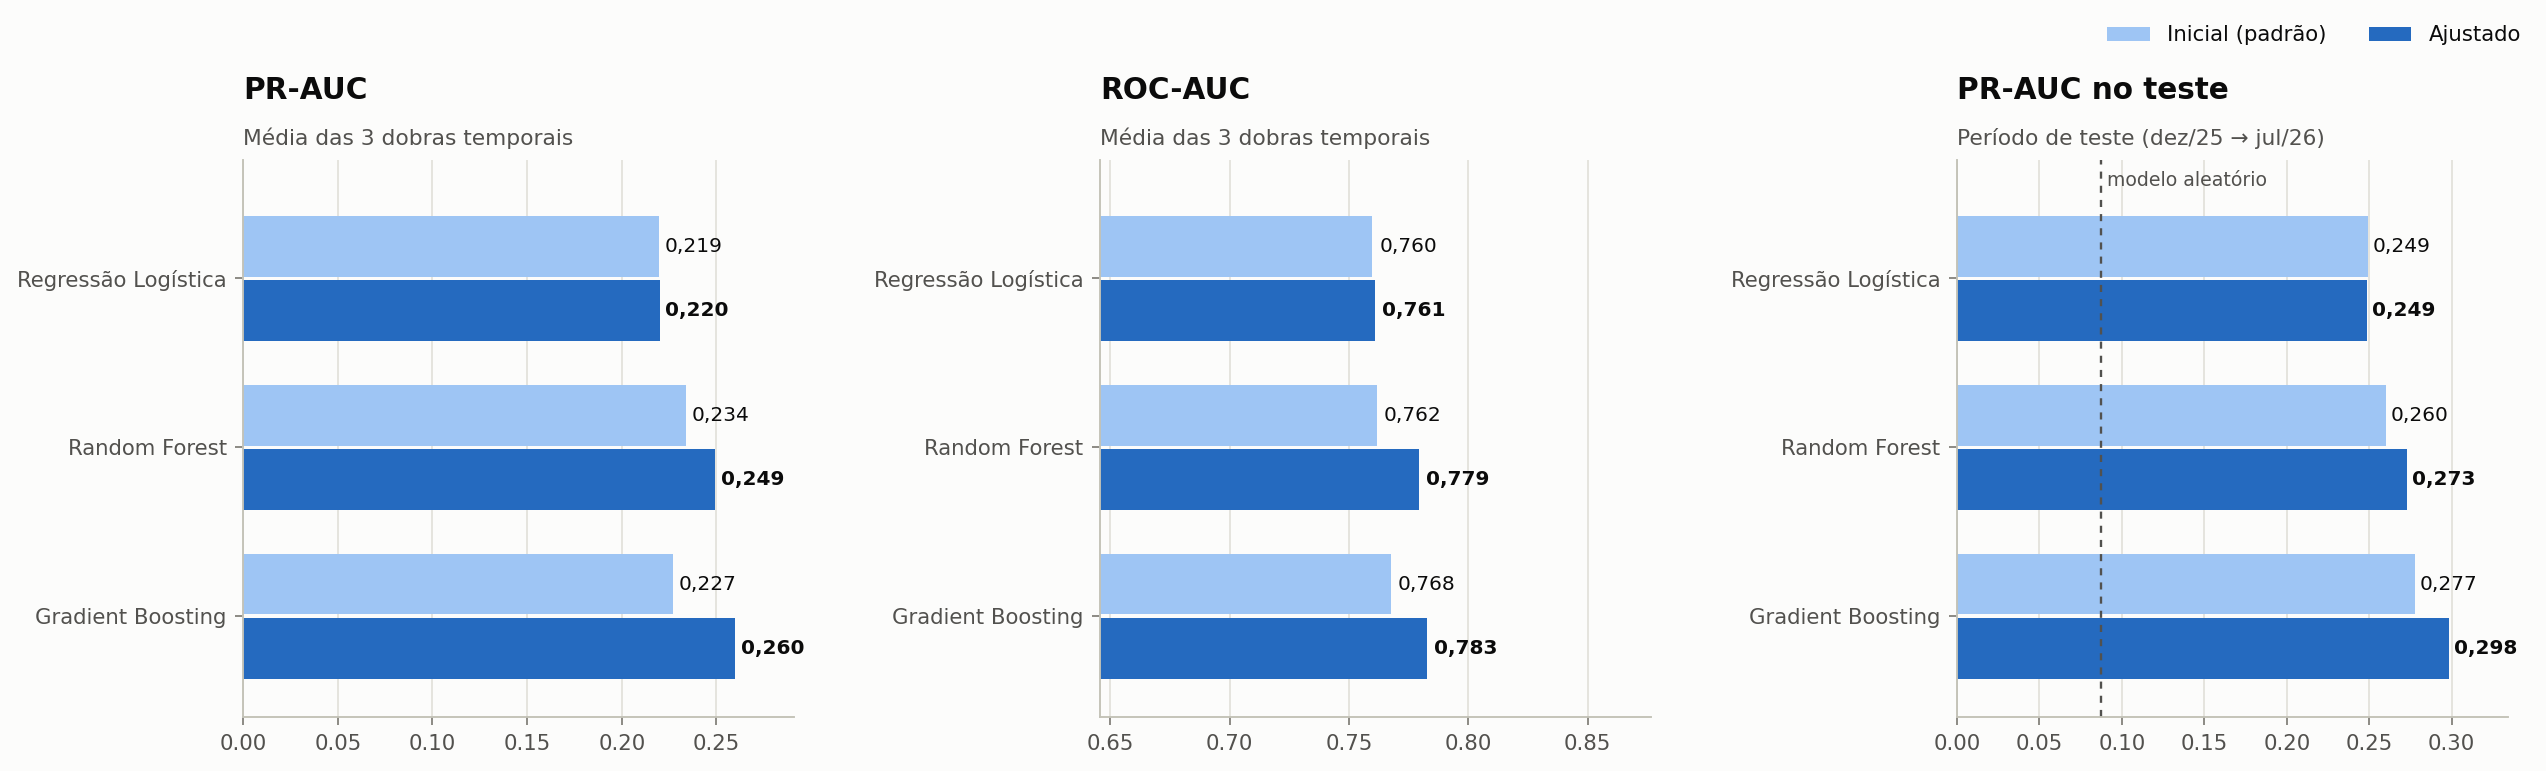

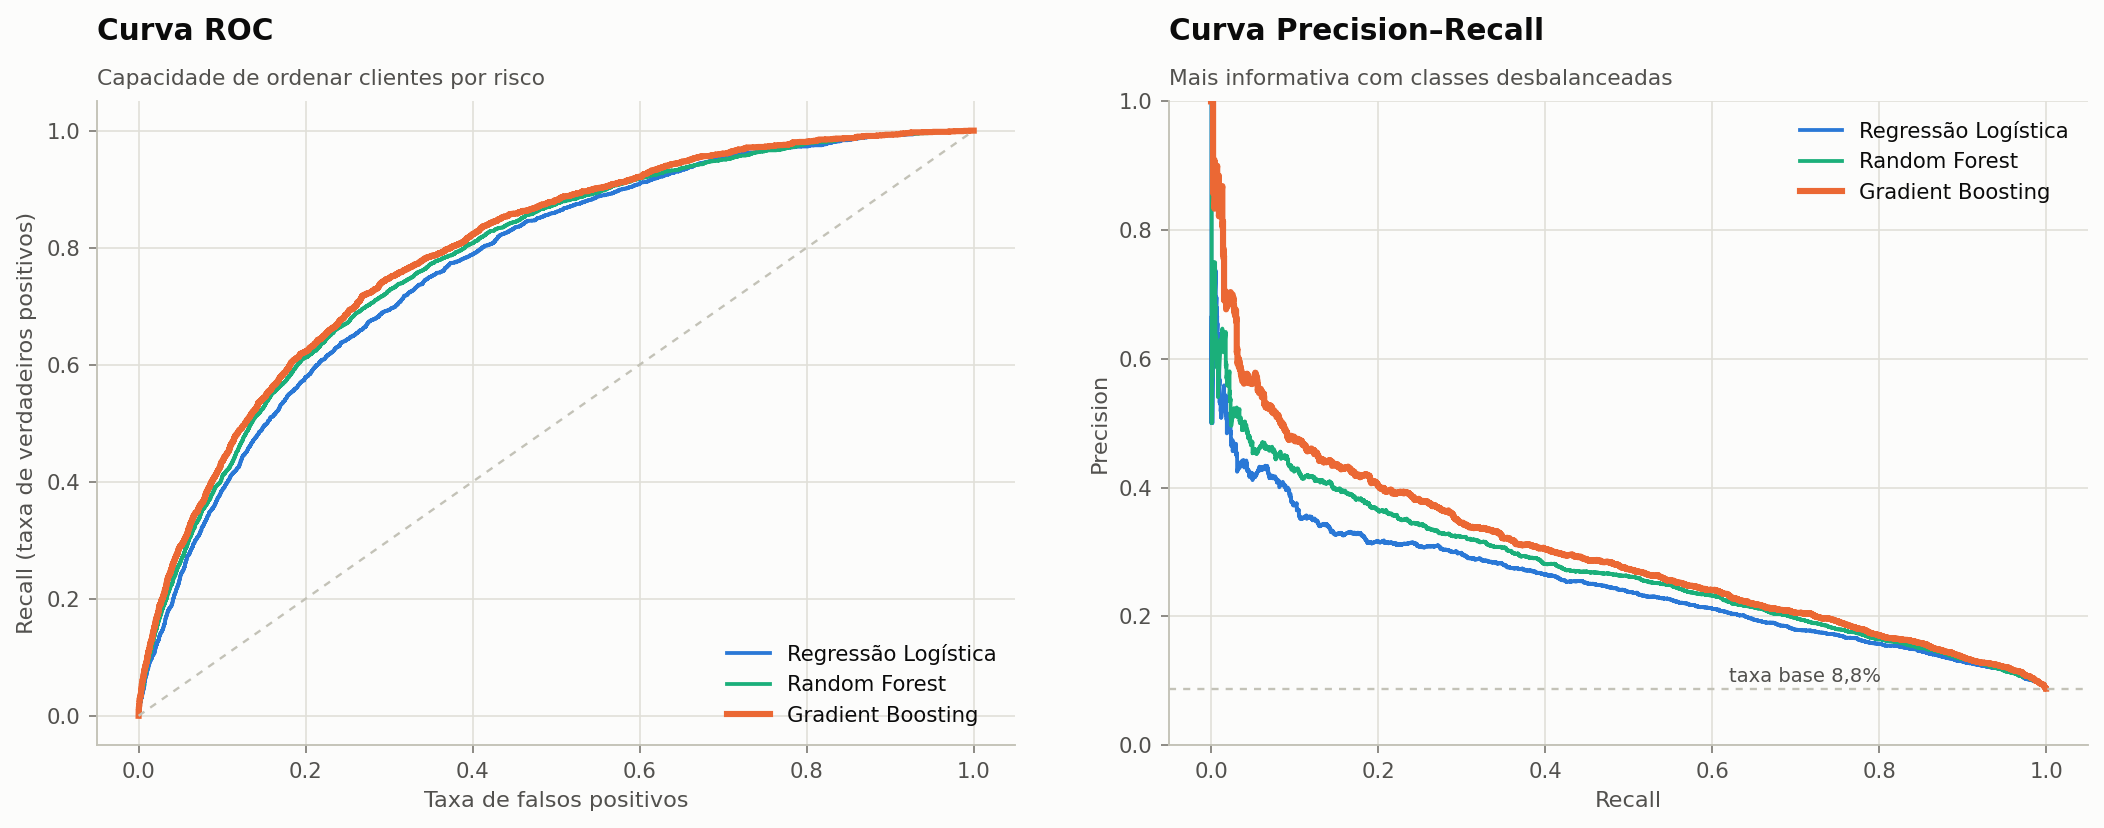

In [4]:
rows = []
for k, v in results["tuned"].items():
    rows.append({"modelo": v["name"],
                 "CV PR-AUC inicial": results["baseline"][k]["cv"]["pr_auc"], "CV PR-AUC ajustado": v["cv"]["pr_auc"],
                 "teste ROC-AUC": v["test"]["roc_auc"], "teste PR-AUC": v["test"]["pr_auc"], "teste Brier": v["test"]["brier"]})
display(pd.DataFrame(rows).round(4))
display(Image(FIG / "01_comparacao_modelos.png"))
display(Image(FIG / "02_curvas_roc_pr.png"))

In [5]:
pd.DataFrame([{"modelo": v["name"], **v["best_params"]} for v in results["tuned"].values()])

,modelo,C,l1_ratio,solver,max_depth,max_features,min_samples_leaf,n_estimators,early_stopping,l2_regularization,learning_rate,max_iter,max_leaf_nodes
0,Regressão Logística,0.253782,1.0,saga,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Random Forest,NaN,NaN,NaN,NaN,0.300000,42.0,300.0,NaN,NaN,NaN,NaN,NaN
2,Gradient Boosting (HistGradientBoosting),NaN,NaN,NaN,NaN,0.471757,24.0,NaN,False,3.538759,0.04115,280.0,8.0


## 4. Desbalanceamento
Reamostragem e pesos deslocam as probabilidades sem melhorar a ordenação — e destroem a calibração.

,modelo,estrategia,pr_auc,roc_auc,recall,precision,prob_media,brier
0,Regressão Logística,Nenhuma,0.219,0.760,0.025,0.373,0.082,0.066
1,Regressão Logística,class_weight='balanced',0.217,0.761,0.701,0.154,0.400,0.199
2,Regressão Logística,Random oversampling,0.217,0.762,0.698,0.154,0.399,0.198
3,Regressão Logística,Random undersampling,0.212,0.755,0.714,0.152,0.406,0.205
4,Regressão Logística,SMOTE,0.217,0.759,0.706,0.154,0.388,0.198
5,Random Forest,Nenhuma,0.234,0.762,0.014,0.457,0.092,0.065
6,Random Forest,class_weight='balanced',0.218,0.766,0.003,0.437,0.078,0.065
7,Random Forest,Random oversampling,0.221,0.765,0.028,0.379,0.113,0.067
8,Random Forest,Random undersampling,0.216,0.769,0.715,0.155,0.410,0.194
9,Random Forest,SMOTE,0.221,0.761,0.038,0.415,0.124,0.069


,estrategia,pr_auc,brier,prob_media
0,Nenhuma,0.2600,0.0639,0.0807
1,class_weight='balanced',0.2506,0.1683,0.3535
2,SMOTE,0.2536,0.0655,0.1061


Estratégia adotada: Nenhuma


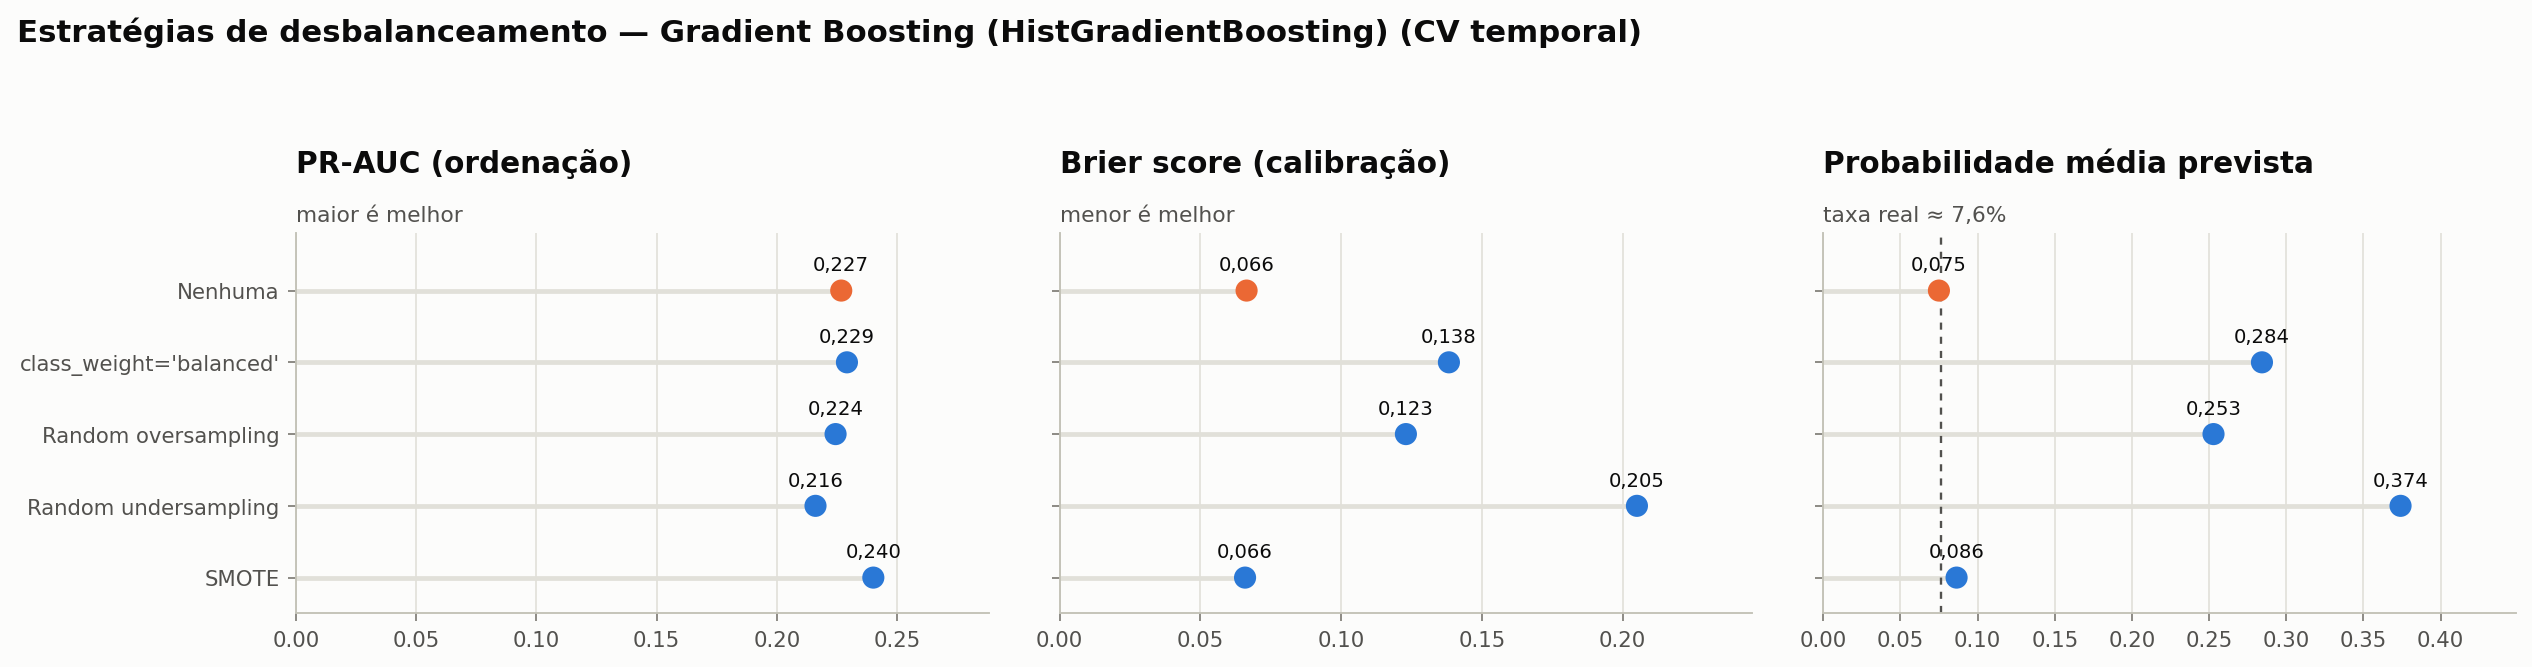

In [6]:
imb = pd.DataFrame(results["imbalance"])[["modelo", "estrategia", "pr_auc", "roc_auc", "recall", "precision", "prob_media", "brier"]]
display(imb.round(3))
display(pd.DataFrame(results["imbalance_tuned"])[["estrategia", "pr_auc", "brier", "prob_media"]].round(4))
print("Estratégia adotada:", results["imbalance_strategy"])
display(Image(FIG / "03_desbalanceamento.png"))

## 5. Threshold
Escolhido com previsões *out-of-fold* do treino, maximizando o resultado esperado da campanha.

In [7]:
print("Threshold operacional:", meta["threshold"], "\nFaixas de risco:", meta["risk_thresholds"])
pd.DataFrame(results["threshold_test_table"]).round(3)

Threshold operacional: {'operacional': 0.23, 'f1_otimo': 0.17, 'criterio': 'máximo resultado líquido esperado (OOF do treino)'} 
Faixas de risco: {'medio': 0.12, 'alto': 0.23}


,threshold,precision,recall,f1,abordados,percentual_abordados,churns_identificados,churns_totais,fp,fn,resultado_liquido
0,0.10,0.226,0.631,0.333,6787,0.244,1535,2434,5252,899,89717.98
1,0.12,0.250,0.566,0.347,5513,0.198,1378,2434,4135,1056,111092.40
2,0.20,0.319,0.359,0.338,2735,0.098,873,2434,1862,1561,105531.66
3,0.23,0.342,0.303,0.321,2157,0.078,738,2434,1419,1696,97987.74
4,0.30,0.409,0.196,0.265,1170,0.042,478,2434,692,1956,79235.22
5,0.40,0.479,0.092,0.154,466,0.017,223,2434,243,2211,47176.08
6,0.50,0.571,0.041,0.077,175,0.006,100,2434,75,2334,26164.86
7,0.60,0.705,0.018,0.034,61,0.002,43,2434,18,2391,14034.44
8,0.70,0.875,0.006,0.011,16,0.001,14,2434,2,2420,4167.30


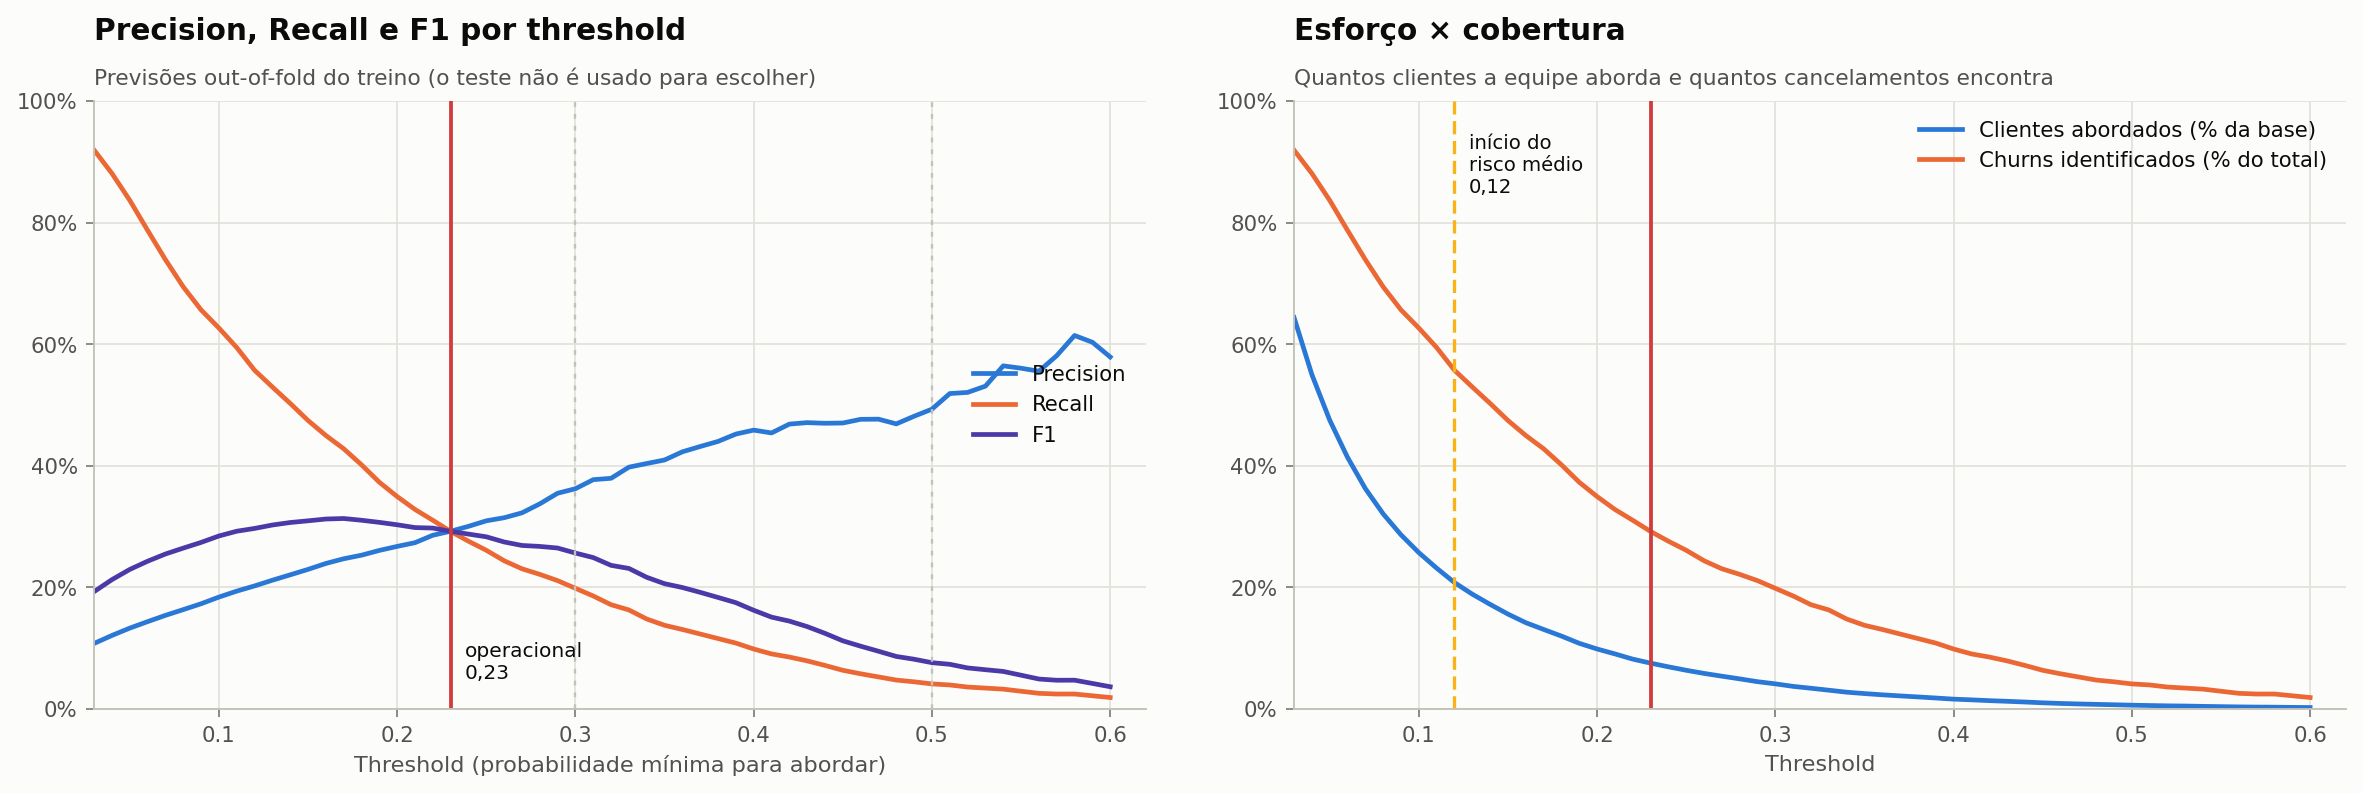

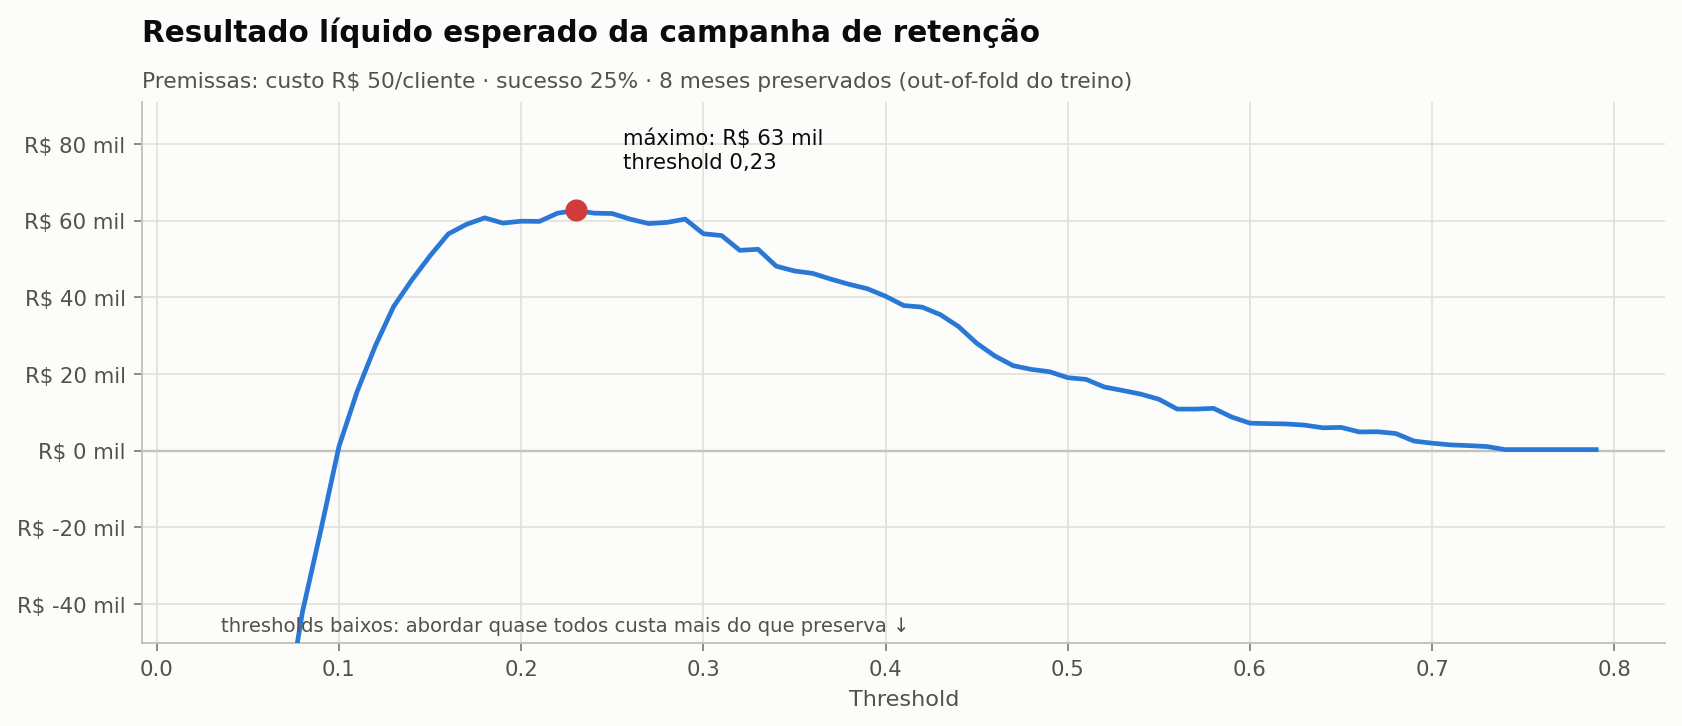

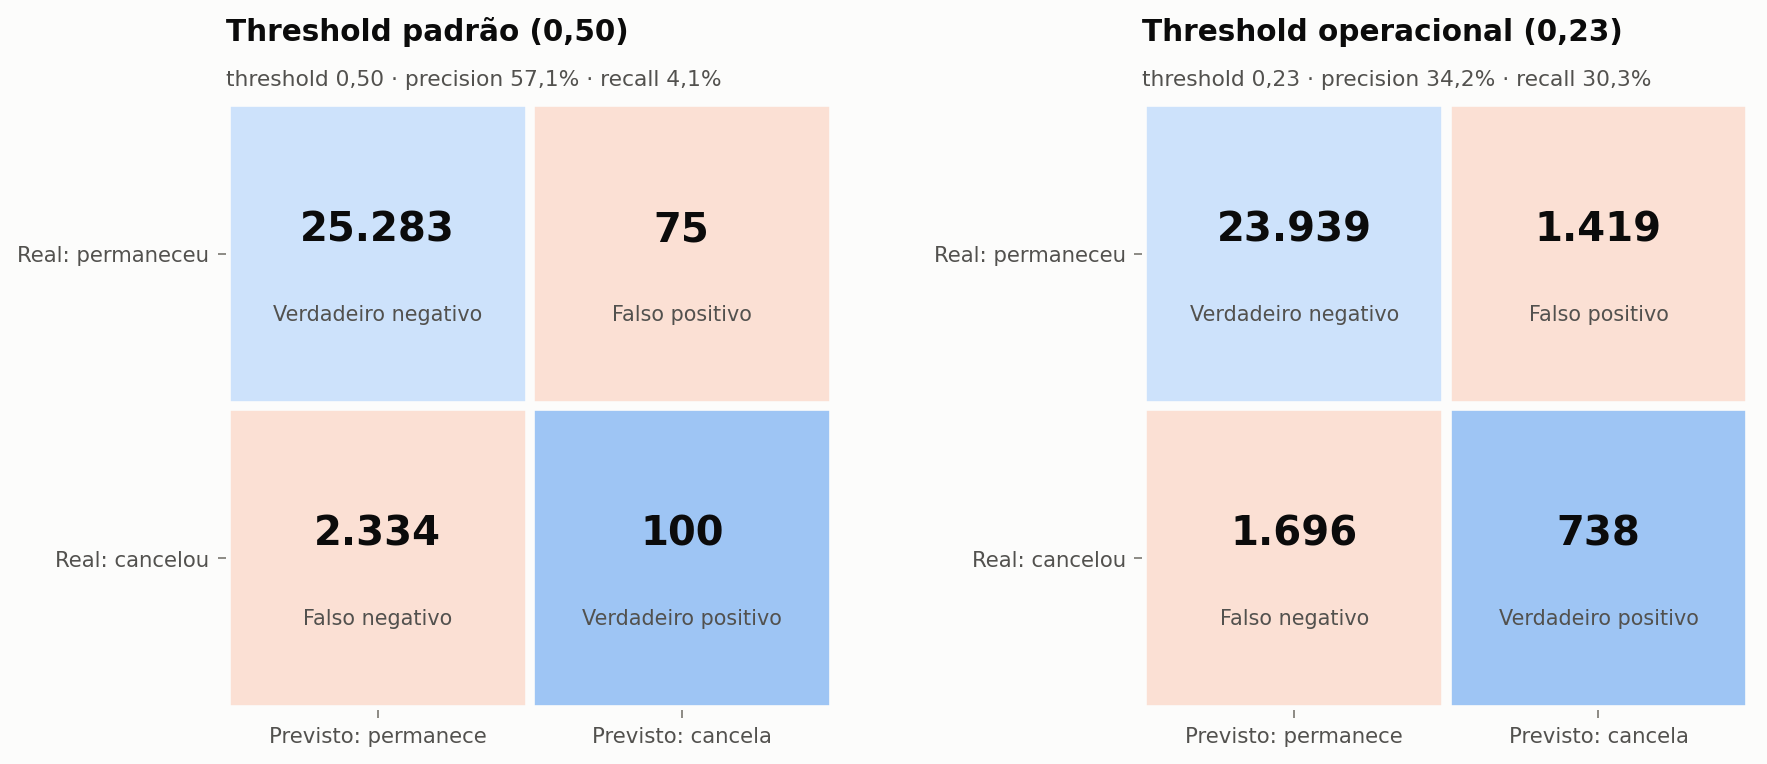

In [8]:
display(Image(FIG / "05_threshold.png")); display(Image(FIG / "06_valor_negocio.png")); display(Image(FIG / "04_matriz_confusao.png"))

## 6. Níveis de risco, lift e calibração

,risco,clientes,churns,taxa_real
0,Alto,2157,738,0.342142
1,Médio,3356,640,0.190703
2,Baixo,22279,1056,0.047399


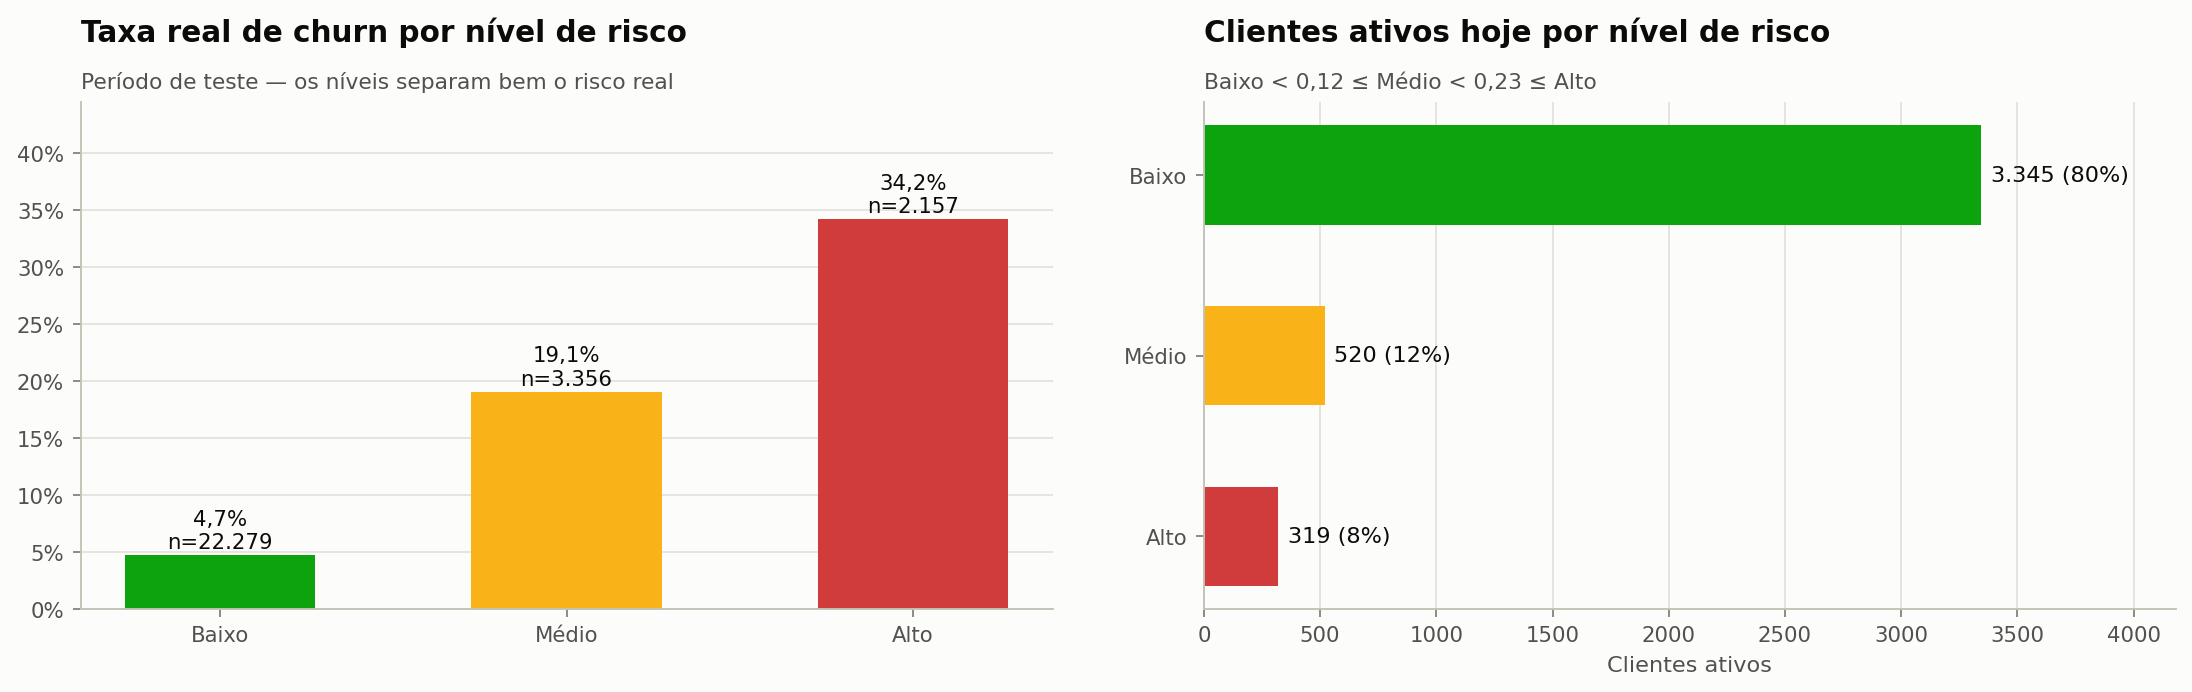

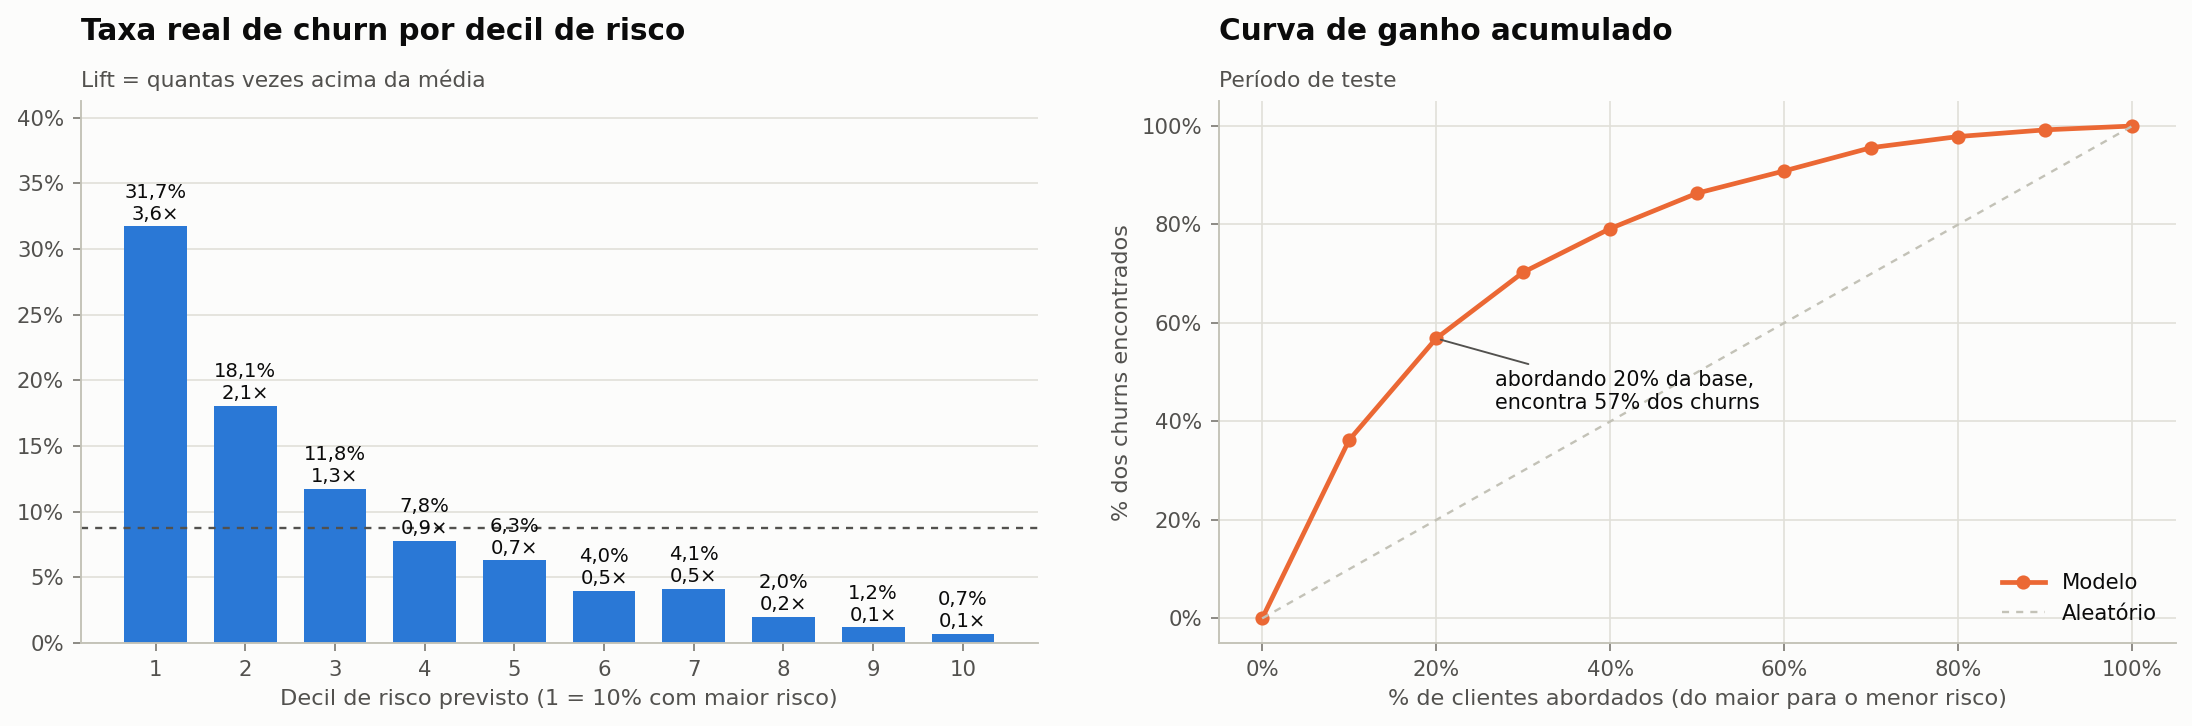

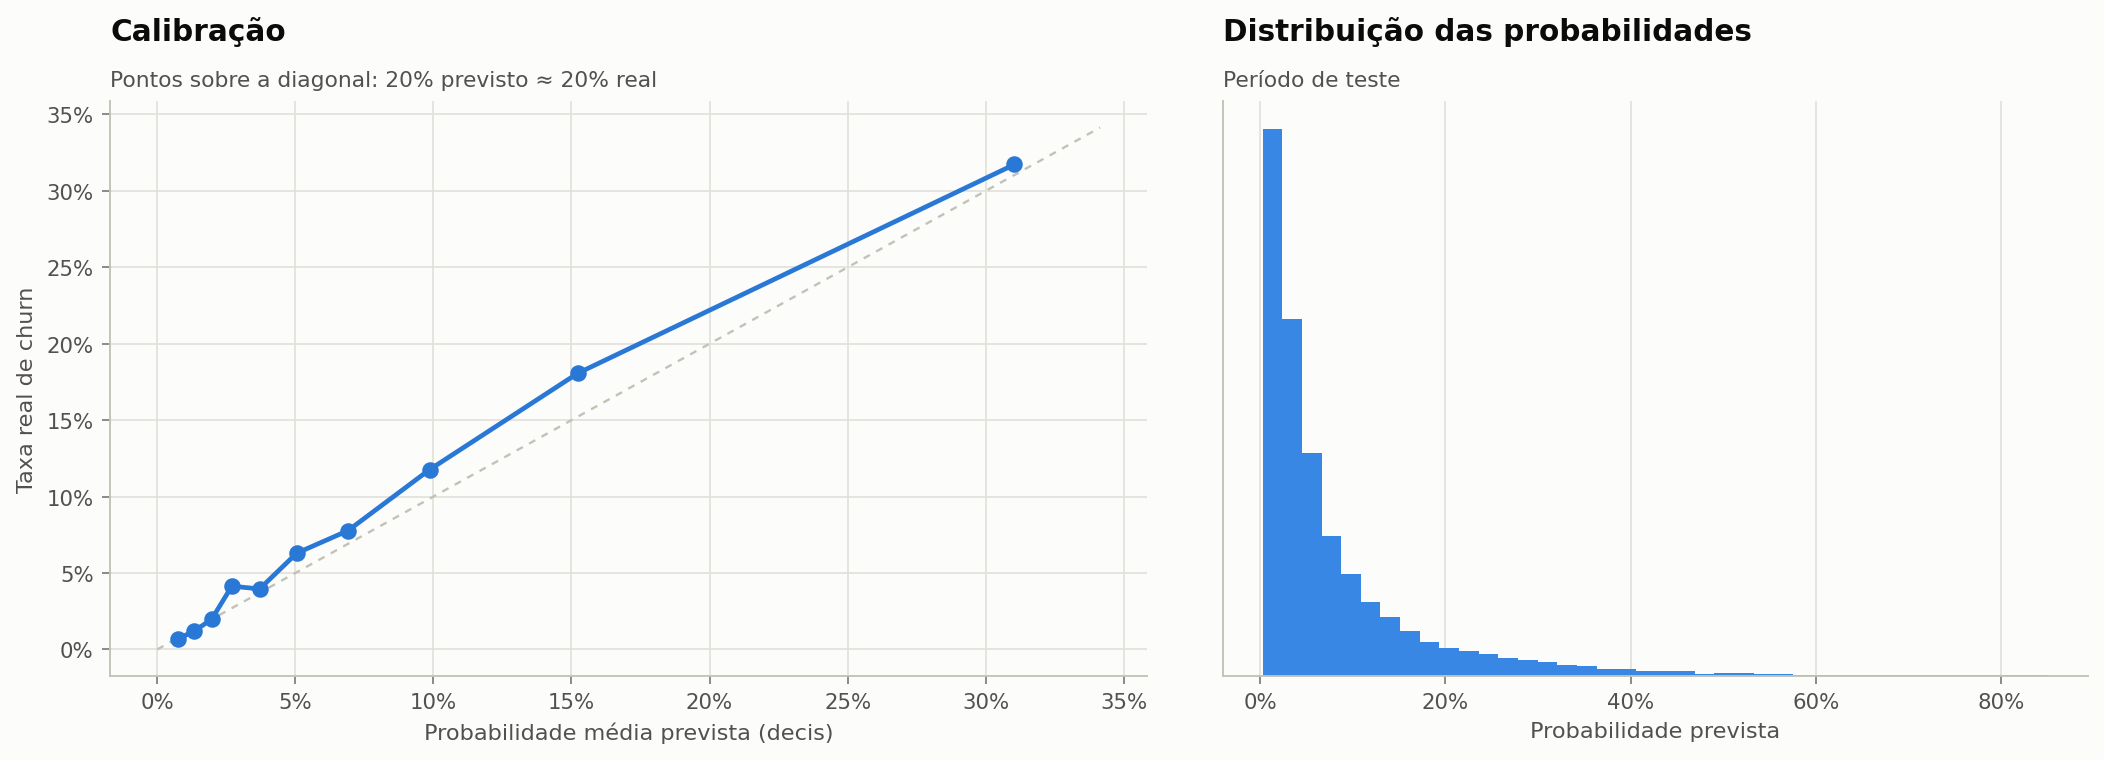

In [9]:
display(pd.DataFrame(results["risk_summary_test"]))
display(Image(FIG / "09_niveis_risco.png")); display(Image(FIG / "08_ganho_lift.png")); display(Image(FIG / "07_calibracao.png"))

## 7. Explicabilidade global

,label,importance,std
0,Janela de renovação do contrato,0.1280,0.0053
1,Dias ativos no mês,0.0891,0.0035
2,Forma de pagamento,0.0087,0.0015
3,Tempo como cliente,0.0085,0.0038
4,Variação de uso no último mês,0.0076,0.0005
5,Tipo de contrato,0.0073,0.0025
6,Nota de satisfação,0.0064,0.0008
7,Tempo desde o último chamado,0.0057,0.0030
8,Uso das funcionalidades do plano,0.0047,0.0011
9,Variação do tempo de uso,0.0037,0.0003


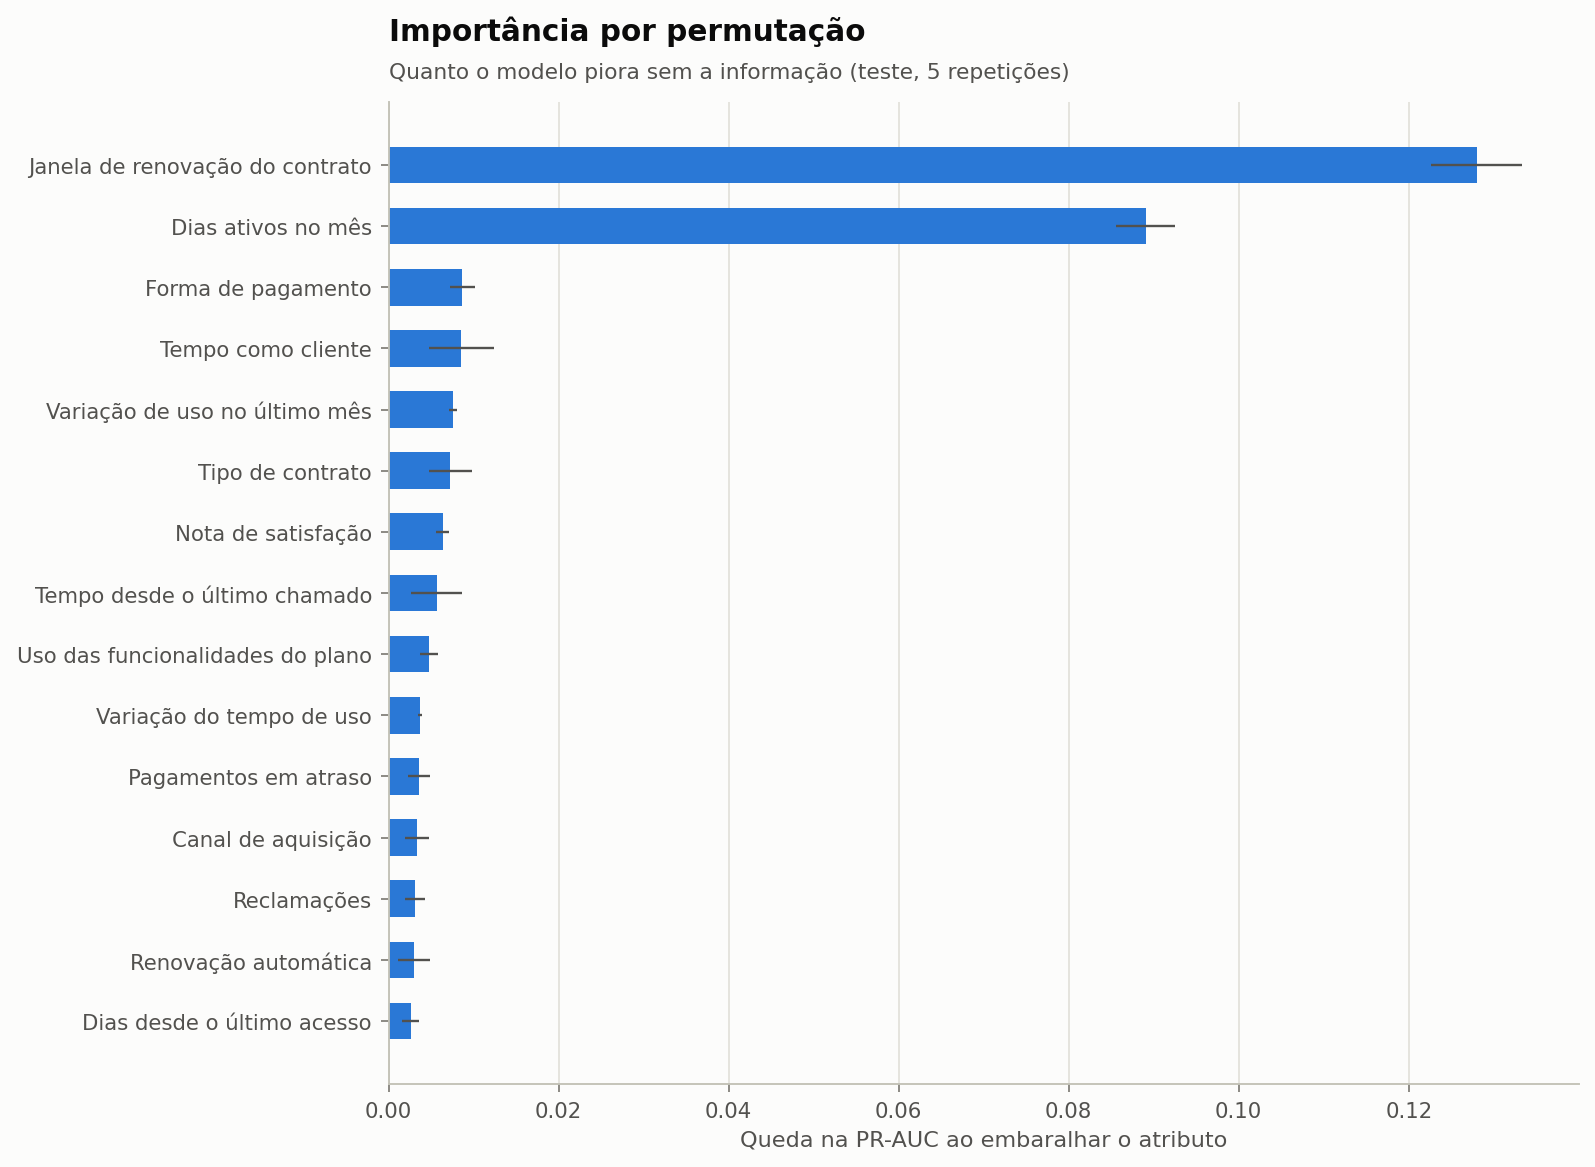

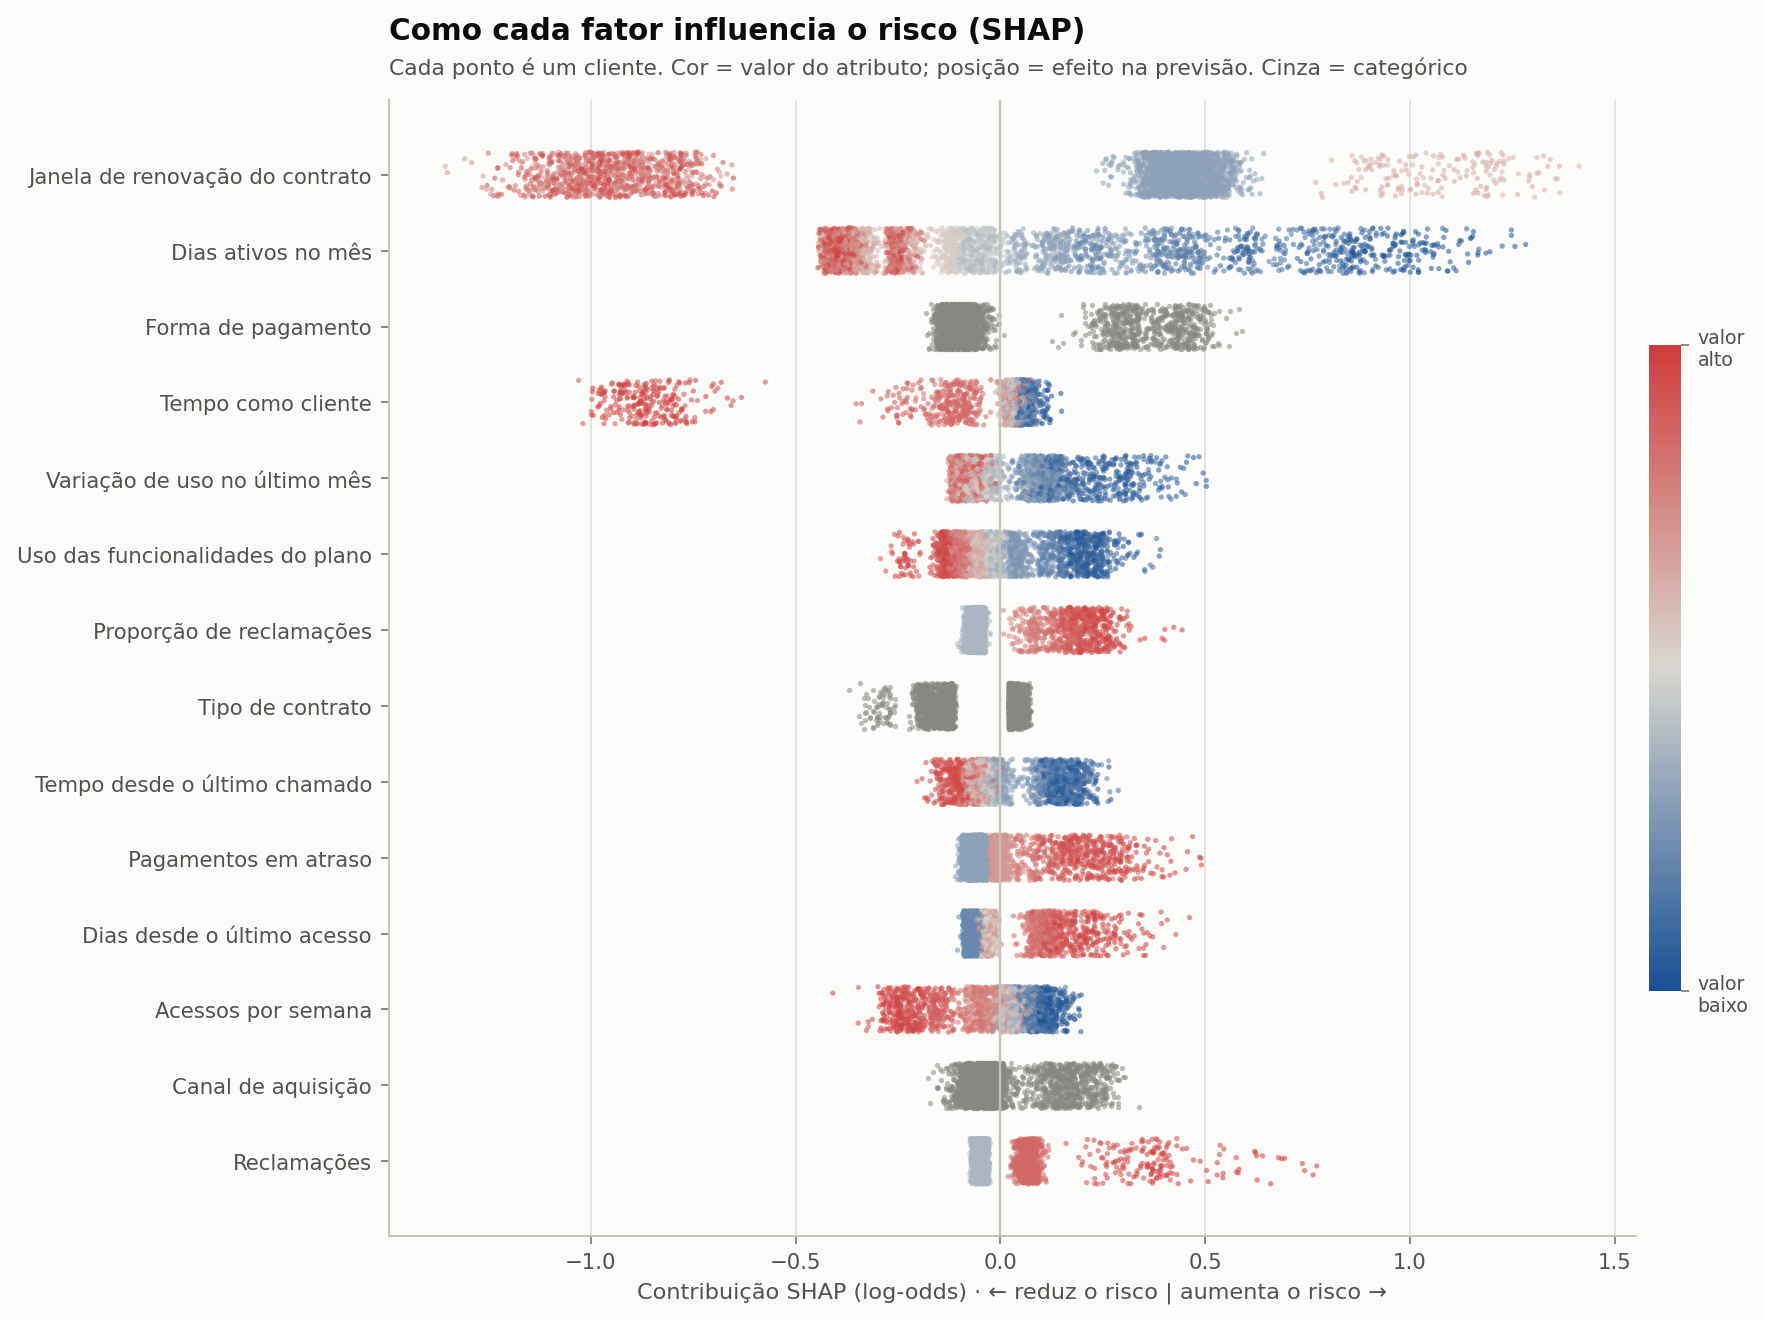

In [10]:
display(pd.DataFrame(results["permutation_importance"]).head(12)[["label", "importance", "std"]].round(4))
display(Image(FIG / "10_importancia_permutacao.png")); display(Image(FIG / "11_shap_resumo.png"))

## 8. Usando o modelo: previsão, explicação individual e threshold configurável

In [11]:
scorer = ChurnScorer.load()
clientes = pd.read_parquet(config.SCORING_BASE_FILE)
pred = scorer.predict(clientes)
clientes = clientes.join(pred)
clientes.sort_values("probabilidade", ascending=False)[["customer_id", "nome", "plano", "valor_mensal", "probabilidade", "nivel_risco"]].head(10)

,customer_id,nome,plano,valor_mensal,probabilidade,nivel_risco
4179,CLI-08995,Prisma Saúde ME,Profissional,185.21,0.772435,Alto
1463,CLI-03113,Paula Almeida,Profissional,169.91,0.739055,Alto
248,CLI-00532,Âncora Contabilidade Ltda,Profissional,169.91,0.707406,Alto
3436,CLI-07443,Trilha Tecnologia Ltda,Empresarial,424.91,0.697447,Alto
3525,CLI-07622,Débora Dias,Profissional,169.91,0.683306,Alto
351,CLI-00736,Lucas Moreira,Básico,42.41,0.680490,Alto
1120,CLI-02335,Beatriz Siqueira,Básico,46.23,0.629048,Alto
3636,CLI-07850,Samuel Teixeira,Básico,42.41,0.588941,Alto
1595,CLI-03392,Pedro Martins,Básico,42.41,0.585645,Alto
2492,CLI-05337,Renato Duarte,Profissional,169.91,0.570719,Alto


In [12]:
alvo = clientes.sort_values("probabilidade", ascending=False).iloc[[3]]
exp = scorer.explain(alvo)[0]
print(f"Cliente {alvo.customer_id.iloc[0]} — probabilidade estimada de cancelamento: {exp['probabilidade']:.0%} ({exp['nivel_risco']} risco)")
print("\nFatores que aumentam o risco:")
for f in exp["fatores_risco"]: print("  •", f["text"])
print("\nFatores que reduzem o risco:")
for f in exp["fatores_protecao"]: print("  •", f["text"])
print("\nSugestão:", exp["recomendacao"]["acao_sugerida"])
print(exp["recomendacao"]["prioridade"])
print("⚠", exp["recomendacao"]["aviso"])

Cliente CLI-07443 — probabilidade estimada de cancelamento: 70% (Alto risco)

Fatores que aumentam o risco:
  • renovação do contrato anual em 2 meses
  • ativo em apenas 10 dias no último mês
  • pagamento via boleto
  • nota de satisfação 5/10

Fatores que reduzem o risco:
  • Tipo de contrato: Anual
  • Canal de aquisição: Orgânico
  • Renovação automática: Sim

Sugestão: Iniciar conversa de renovação com antecedência, mostrando resultados obtidos com o produto.
Prioridade alta — sugerido contato humano em até 48h.
⚠ Sugestão baseada em padrões dos dados. A decisão final é da equipe responsável.


/usr/local/lib/python3.11/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [13]:
for t in (0.3, 0.5, 0.7, meta["threshold"]["operacional"]):
    n = scorer.predict(clientes, threshold=t).acima_do_threshold.sum()
    print(f"threshold {t:.2f} → {n:>4} clientes sinalizados para abordagem")

threshold 0.30 →  161 clientes sinalizados para abordagem
threshold 0.50 →   16 clientes sinalizados para abordagem


threshold 0.70 →    3 clientes sinalizados para abordagem


threshold 0.23 →  319 clientes sinalizados para abordagem


## 9. Simulação de retenção
> **Simulação hipotética**: mostra como o modelo reagiria se os sinais fossem diferentes. Não é uma previsão garantida do comportamento do cliente.

In [14]:
c = alvo.drop(columns=pred.columns)
cenarios = {
    "Uso volta ao nível de 3 meses atrás": {"acessos_m1": float(c.acessos_m4.iloc[0]), "acessos_m2": float(c.acessos_m5.iloc[0]),
                                            "dias_ativos_m1": 22},
    "Sem atrasos de pagamento": {"faturas_atrasadas_6m": 0, "dias_atraso_medio_6m": 0, "faturas_em_aberto": 0},
    "Sem reclamações": {"reclamacoes_6m": 0},
    "Migra para débito automático": {"forma_pagamento": "Débito automático", "renovacao_automatica": 1},
}
pd.DataFrame([{"cenário": k, **simulate(scorer, c, v)} for k, v in cenarios.items()]).drop(columns="aviso").round(3)

,cenário,probabilidade_atual,probabilidade_simulada,variacao_pontos_percentuais,nivel_atual,nivel_simulado
0,Uso volta ao nível de 3 meses atrás,0.697,0.299,-39.875,Alto,Alto
1,Sem atrasos de pagamento,0.697,0.625,-7.214,Alto,Alto
2,Sem reclamações,0.697,0.697,0.000,Alto,Alto
3,Migra para débito automático,0.697,0.598,-9.951,Alto,Alto


## 10. Conclusões

- O **Gradient Boosting ajustado** foi o melhor em PR-AUC na validação cruzada e no teste, com probabilidades calibradas.
- Desbalanceamento tratado **no threshold**, não nos dados, preservando probabilidades interpretáveis.
- Threshold operacional escolhido por valor de negócio, com premissas explícitas e configuráveis.
- Explicações individuais em linguagem de negócio + sugestão de ação, sempre como **apoio à decisão humana**.